# Retail Inventory & Demand Forecasting — Corrected Build v4 (final)

Fourth and final build. v1 was rebuilt into v2 after a diagnostic pass; v2 was independently audited and
**failed on its headline claim**, producing v3; v3 was audited again and **failed on its self-checks and on
model selection**, producing this build. Three rounds of audit are recorded in S0.

**Headline finding up front:** once you remove everything a forecaster could not actually know on the day it
plans, this dataset has very little forecastable signal. Demand is near-deterministic in same-day `Price`
*within each Store x Product series* — and the relationship runs the wrong way round (higher price, higher
demand), which means `Price` was almost certainly generated *from* `Demand` when the dataset was synthesised.
Any model given same-day `Price` scores R^2 ~ 0.9 by reverse-engineering that generator, not by forecasting.

## 0. Defect register — what was wrong and what changed

### Round 1 — diagnosis of the original notebook and report (fixed in v2)
| # | Defect | Evidence | Fix |
|---|---|---|---|
| D1 | `Category` is an attribute of **(Store, Product)**, not of Product. All 100 (Store, Product) groups hold exactly one category, while individual Product IDs span **2 to 5** categories (only P0003 and P0016 span all 5). | groupby nunique | The original notebook's global majority-vote "fix" is **removed**; raw categories are used. |
| D2 | That majority-vote relabels **~50% of rows**. Seven products have tied top categories, so the damage depends on an arbitrary tie-break: alphabetical-first gives Toys **-64%**, Furniture -32%, Groceries +26%; alphabetical-last gives Clothing **-100%**, Toys +56%. | tie-break comparison | Category series now reconcile exactly to raw (verified against the CSV on disk in S9). |
| D3 | `Demand` is uncensored; `Units Sold` is censored by inventory (11.4% of rows at the cap). | truncation check | Forecast target is **`Demand`**. |
| D4 | The report's regression (MAE 18.51 / MSE 586.61 / **R^2 0.7033**) is **circular** — it predicts demand from the sales that demand produced. Its R^2 sits right on corr(Demand, Units Sold)^2 = **0.6946**. The exact figures are **not** reproducible (closest: R^2 0.7011 / MAE 19.06 / MSE 660.0), so the feature set differed, but the family is unmistakable. | S8 | Documented as a defect, not carried forward. |
| D5 | The original LightGBM used same-day `Inventory Level`/`Units Ordered` and used the **test set for early stopping**. | feature list | Separate validation window; target proxies removed. |
| D6 | `IsHoliday` was a hard-coded constant 0. | notebook cell | Real **US federal holiday calendar** joined (28 dates in window). |
| D7 | `Seasonality` is a deterministic function of calendar month. | crosstab | Treated as redundant with `Month`. |
| D8 | **No wastage field exists**, but the report's KPI list requires wastage %. | column list | Clearly-labelled **synthetic** series (S7); every column suffixed `_SYNTH`. |
| D9 | Data spans **760 days (2.08 years)**, not the "three fiscal years (2022-2024)" the report claims. | date range | Stated as-is. |
| D10 | Lead time / review period / service level are **not in the data**. | - | Documented defaults **plus a full sensitivity grid**. |

### Round 2 — independent audit of v2 (fixed here in v3)
| # | Defect in v2 | Evidence | Fix in v3 |
|---|---|---|---|
| E1 | **"Leakage-free LightGBM, R^2 0.918" was not leakage-free.** Its accuracy comes from same-day `Price` and `Competitor Pricing`. History alone gives R^2 ~0.20. | ablation | Models are split into three **information tiers** (S5). The "all same-day" tier is reported but disqualified. |
| E2 | **`Price` is generated from `Demand`.** Within-series the price-demand slope is **positive in 100 of 100 series**; mean correlation **0.797 at lag 0** but **0.225 one day apart**. | lag correlation (S5.1) | Quantified in S5.1; Tier B is flagged as contaminated. |
| E3 | LightGBM was **one-step-ahead with true lag-1 inside the test window**, then compared against ARIMA/Prophet forecasting 92 days out. | split inspection | LightGBM now runs **recursive 92-day multi-step**; the one-step number is reported separately and labelled. |
| E4 | **Best model was selected on test MAPE**, then reused for the policy and backtest. | code | Selection now happens on a **validation window**; test is touched once. |
| E5 | ARIMAX / Prophet+regressors were fed **realised** future `promo_share` and `epidemic`. | code | Relabelled **"scenario oracle"** and excluded from headline comparison; kept as an upper bound. |
| E6 | **Early stopping never fired** (hit the 2000 cap); `subsample` was inert because `bagging_freq=0`. | best_iteration | Learning rate and cap retuned, `bagging_freq=1`. |
| E7 | **Section-10 assertions were vacuous** — they compared a dataframe with itself, or tested a hard-coded list against itself. | audit | S9 rewritten: reloads exported CSVs **from disk** and recomputes from the **raw CSV**. |
| E8 | Category-day aggregation **hid row-level error**. On v4's Tier A recursive the gap is roughly **23% aggregated vs 53% row-level MAPE** (printed in S5.2). | recompute | Both reported side by side. |
| E9 | Single seed; LightGBM R^2 moved 0.918 -> 0.926 on a seed change. | audit | **Multi-seed run** with reported spread. |

### Round 3 — independent audit of v3 (fixed here in v4)
| # | Defect in v3 | Fix in v4 |
|---|---|---|
| F1 | **Model selection excluded the baselines.** On validation a flat baseline beat both ARIMA and Prophet in Clothing, Electronics and Furniture, yet selection was restricted to ARIMA vs Prophet, so the policy ran on models that were not the validation winners. | Selection now runs over **all four legitimate models** (2 baselines + ARIMA + Prophet). |
| F2 | The summary's "best legitimate model" was an **argmin over test MAPE** — quietly undoing the validation-selection fix. | Removed. The summary reports the validation-selected model and its test score only. |
| F3 | **"Gap attributable to unknowable columns = 0.818 R^2" was mislabelled** — it mixed modes and blamed the wrong columns. Tier B (own `Price`) already reaches 0.92; competitor/weather/epidemic add only ~0.01. | Attribution corrected and computed mode-for-mode (S5.2). |
| F4 | **Stale v2 numbers in the markdown** (E2, E8, D2, D4) never updated after the rebuild. | All recomputed; E2/E8/D2 now carry v4 values and D4 is restated accurately. |
| F5 | **D4 overclaimed.** The report's figures are *not* exactly reproduced — closest is R^2 0.7011 / MAE 19.06 / MSE 660.0 against the stated 0.7033 / 18.51 / 586.61. | Restated as "same family, not an exact match". |
| F6 | A **per-series mean with no model at all** beats the "honest" Tier A model (R^2 0.132 vs 0.117). | Added as an explicit baseline (S5.2). This is now the headline finding. |
| F7 | **Safety stock used the SD of demand, not of forecast error** — the wrong quantity for a reorder point. | Recomputed from **validation-window forecast-error SD**. |
| F8 | **8 of 12 verification assertions were weak, tautological or testing the wrong object**; the recursion check was a row count that a leaky run would also pass. | Rewritten in S9, including a **poison test** that corrupts test-window demand and asserts the forecast is bit-identical. |
| F9 | **E6 only partly fixed** — Tiers B and C still ran to the 3000-tree cap. | Reported honestly per tier rather than claimed fixed. |
| F10 | **Mismatched information sets**: LightGBM fit on train only, ARIMA/Prophet refit on train+val. | LightGBM **refit on train+val** at the validation-chosen iteration count. |
| F11 | Wastage percentages used **two different denominators under similar names**. | Both renamed to state their denominator. |
| F12 | The recursive headline was **single-seed**. | Recursive forecast now run across 3 seeds with the spread reported. |

In [1]:
import warnings, logging, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import holidays as pyholidays, lightgbm as lgb

warnings.filterwarnings("ignore")
for _n in ("cmdstanpy", "prophet"):
    logging.getLogger(_n).setLevel(logging.ERROR); logging.getLogger(_n).disabled = True

DATA_CANDIDATES = [Path("sales_data.csv"),
                   Path("/kaggle/input/retail-store-inventory-and-demand-forecasting/sales_data.csv")]
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
SEED, SEEDS = 42, [42, 7, 2024]
TARGET, TEST_MONTHS, VAL_MONTHS = "Demand", 3, 3
LEAD_TIME_DAYS, REVIEW_PERIOD_DAYS, SERVICE_LEVEL = 7, 7, 0.95
LEAD_TIME_GRID, SERVICE_GRID = [3, 5, 7, 10, 14], [0.90, 0.95, 0.99]

rng = np.random.default_rng(SEED)
DATA_PATH = next(p for p in DATA_CANDIDATES if p.exists())
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
FMT = {"MAE": "{:,.1f}", "RMSE": "{:,.1f}", "MAPE (%)": "{:.2f}"}
def mape(y, p): return float(np.mean(np.abs((np.asarray(y, float) - p) / np.asarray(y, float))) * 100)
def score(y, p): return {"MAE": mean_absolute_error(y, p),
                         "RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAPE (%)": mape(y, p)}
print("Data:", DATA_PATH, "| target:", TARGET)

Importing plotly failed. Interactive plots will not work.


Data: sales_data.csv | target: Demand


## 1. Load, audit, clean

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
RAW_ROWS = len(df)
cats_per_product = df.groupby("Product ID").Category.nunique()
audit = {
    "rows": len(df), "date_min": str(df.Date.min().date()), "date_max": str(df.Date.max().date()),
    "n_days": int(df.Date.nunique()), "span_years": round(df.Date.nunique()/365.25, 2),
    "stores": int(df["Store ID"].nunique()), "products": int(df["Product ID"].nunique()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_panel_keys": int(df.duplicated(["Date", "Store ID", "Product ID"]).sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "negative_inventory": int((df["Inventory Level"] < 0).sum()),
    "sold_gt_inventory": int((df["Units Sold"] > df["Inventory Level"]).sum()),
    "sold_eq_inventory_pct": round(100*(df["Units Sold"] == df["Inventory Level"]).mean(), 2),
    "category_nunique_within_store_product_MAX": int(df.groupby(["Store ID", "Product ID"]).Category.nunique().max()),
    "categories_per_product_min": int(cats_per_product.min()),
    "categories_per_product_max": int(cats_per_product.max()),
    "products_spanning_all_5": int((cats_per_product == 5).sum()),
    "corr_demand_unitssold": round(float(df.Demand.corr(df["Units Sold"])), 4),
}
audit["r2_implied_by_that_corr"] = round(audit["corr_demand_unitssold"]**2, 4)
df["Inventory Level"] = df["Inventory Level"].clip(lower=0)
df["Units Sold"] = df[["Units Sold", "Inventory Level"]].min(axis=1)
print(json.dumps(audit, indent=2))
print("\nD1 detail — categories per Product ID:", cats_per_product.value_counts().sort_index().to_dict())

{
  "rows": 76000,
  "date_min": "2022-01-01",
  "date_max": "2024-01-30",
  "n_days": 760,
  "span_years": 2.08,
  "stores": 5,
  "products": 20,
  "duplicate_rows": 0,
  "duplicate_panel_keys": 0,
  "missing_cells": 0,
  "negative_inventory": 0,
  "sold_gt_inventory": 0,
  "sold_eq_inventory_pct": 11.39,
  "category_nunique_within_store_product_MAX": 1,
  "categories_per_product_min": 2,
  "categories_per_product_max": 5,
  "products_spanning_all_5": 2,
  "corr_demand_unitssold": 0.8334,
  "r2_implied_by_that_corr": 0.6946
}

D1 detail — categories per Product ID: {2: 5, 3: 8, 4: 5, 5: 2}


## 2. Real holiday calendar (D6)

In [3]:
hol = pyholidays.US(years=sorted(df.Date.dt.year.unique()))
hol_df = (pd.Series({pd.Timestamp(d): n for d, n in hol.items()}, name="Holiday_Name")
          .rename_axis("Date").reset_index())
hol_df = hol_df[hol_df.Date.between(df.Date.min(), df.Date.max())].sort_values("Date").reset_index(drop=True)
HOLIDAYS = set(hol_df.Date)
df["IsHoliday"] = df.Date.isin(HOLIDAYS).astype(int)
cal = df.groupby("Date").agg(promo_share=("Promotion", "mean"), epidemic=("Epidemic", "mean"),
                             is_holiday=("IsHoliday", "max")).asfreq("D")
print(f"Real US federal holidays joined: {len(hol_df)} dates ({100*df.IsHoliday.mean():.1f}% of rows)")

Real US federal holidays joined: 28 dates (3.7% of rows)


## 3. Category series and a three-way split
Train fits the models, **validation selects the model**, test is scored once (E4).

In [4]:
daily = df.groupby(["Date", "Category"])[TARGET].sum().unstack("Category").asfreq("D")
sold_daily = df.groupby(["Date", "Category"])["Units Sold"].sum().unstack("Category").asfreq("D")
inv_daily = df.groupby(["Date", "Category"])["Inventory Level"].sum().unstack("Category").asfreq("D")
CATEGORIES = list(daily.columns)

test_start = daily.index.max() - pd.DateOffset(months=TEST_MONTHS)
val_start = test_start - pd.DateOffset(months=VAL_MONTHS)
train_idx = daily.index[daily.index <= val_start]
val_idx = daily.index[(daily.index > val_start) & (daily.index <= test_start)]
test_idx = daily.index[daily.index > test_start]
fit_idx = train_idx.union(val_idx)
print(f"Train {train_idx.min():%Y-%m-%d}..{train_idx.max():%Y-%m-%d} ({len(train_idx)}d)  "
      f"Val {val_idx.min():%Y-%m-%d}..{val_idx.max():%Y-%m-%d} ({len(val_idx)}d)  "
      f"Test {test_idx.min():%Y-%m-%d}..{test_idx.max():%Y-%m-%d} ({len(test_idx)}d)")

Train 2022-01-01..2023-07-30 (576d)  Val 2023-07-31..2023-10-30 (92d)  Test 2023-10-31..2024-01-30 (92d)


## 4. Category-wise ARIMA & Prophet
Two passes. **Pass 1** fits on train and forecasts validation — this is what picks the winner. **Pass 2** refits
on train+val and forecasts test — scored once. The `scenario oracle` variants receive the *realised* future
regressors, so they are an unachievable upper bound (E5), shown for contrast and excluded from selection.

In [5]:
def fit_arima(y, ex_tr=None, ex_te=None, steps=1):
    best = None
    for d in (0, 1):
        for p_ in range(4):
            for q in range(4):
                try: res = ARIMA(y, exog=ex_tr, order=(p_, d, q)).fit()
                except Exception: continue
                if best is None or res.aic < best[0]: best = (res.aic, (p_, d, q), res)
    _, order, res = best
    return np.clip(np.asarray(res.forecast(steps=steps, exog=ex_te)), 0, None), order

def fit_prophet(y, ex_tr=None, ex_te=None, dates=None):
    tr = pd.DataFrame({"ds": y.index, "y": y.values})
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False)
    if ex_tr is not None:
        for c in ex_tr.columns: tr[c] = ex_tr[c].values; m.add_regressor(c)
    m.fit(tr)
    fut = pd.DataFrame({"ds": dates})
    if ex_te is not None:
        for c in ex_te.columns: fut[c] = ex_te[c].values
    return np.clip(m.predict(fut)["yhat"].values, 0, None)

EXOG = ["promo_share", "epidemic", "is_holiday"]
SELECTABLE = ["Baseline: training mean", "Baseline: last 28-day mean", "ARIMA", "Prophet"]
ORACLE = ["ARIMA scenario-oracle (realised regressors)", "Prophet scenario-oracle (realised regressors)"]

def run_models(fit_on, pred_on):
    out = {}
    for c in CATEGORIES:
        y = daily.loc[fit_on, c]; n = len(pred_on)
        ex_f, ex_p = cal.loc[fit_on, EXOG], cal.loc[pred_on, EXOG]
        pr = {"Baseline: training mean": np.full(n, y.mean()),
              "Baseline: last 28-day mean": np.full(n, y.iloc[-28:].mean())}
        pr["ARIMA"], _ = fit_arima(y, steps=n)
        pr["Prophet"] = fit_prophet(y, dates=pred_on)
        pr[ORACLE[0]], _ = fit_arima(y, ex_f, ex_p, n)
        pr[ORACLE[1]] = fit_prophet(y, ex_f, ex_p, pred_on)
        out[c] = pr
    return out

print("Pass 1 — fit on train, forecast validation (model selection)...")
val_pred = run_models(train_idx, val_idx)
val_metrics = pd.DataFrame([{"Category": c, "Model": m, **score(daily.loc[val_idx, c], p)}
                            for c, d_ in val_pred.items() for m, p in d_.items()])
sel = val_metrics[val_metrics.Model.isin(SELECTABLE)]          # F1: baselines compete too
best_model = sel.loc[sel.groupby("Category")["MAPE (%)"].idxmin()].set_index("Category").Model.to_dict()
print("Selected on VALIDATION (all legitimate models compete):")
display(sel.pivot(index="Category", columns="Model", values="MAPE (%)")[SELECTABLE]
        .style.format("{:.2f}").highlight_min(axis=1, color="#c6efce"))
print(best_model)

print("\nPass 2 — refit on train+val, forecast test (scored once)...")
test_pred = run_models(fit_idx, test_idx)
forecast_df = pd.concat([pd.DataFrame({"Date": test_idx, "Category": c, "Model": m,
                                       "Actual": daily.loc[test_idx, c].values, "Forecast": p})
                         for c, d_ in test_pred.items() for m, p in d_.items()], ignore_index=True)
metrics = pd.DataFrame([{"Category": c, "Model": m, **score(daily.loc[test_idx, c], p)}
                        for c, d_ in test_pred.items() for m, p in d_.items()])
best = (metrics[[c_m in best_model.items() for c_m in zip(metrics.Category, metrics.Model)]]
        .rename(columns={"Model": "Selected model (chosen on validation)"}).reset_index(drop=True))
display(best.style.format(FMT))

Pass 1 — fit on train, forecast validation (model selection)...


Selected on VALIDATION (all legitimate models compete):


Model,Baseline: training mean,Baseline: last 28-day mean,ARIMA,Prophet
Category,,,,
Clothing,10.22,8.69,8.82,10.98
Electronics,22.33,23.62,22.48,22.34
Furniture,27.54,30.70,29.96,27.73
Groceries,19.06,30.47,16.66,35.46
Toys,47.45,52.89,47.13,48.03


{'Clothing': 'Baseline: last 28-day mean', 'Electronics': 'Baseline: training mean', 'Furniture': 'Baseline: training mean', 'Groceries': 'ARIMA', 'Toys': 'ARIMA'}

Pass 2 — refit on train+val, forecast test (scored once)...


,Category,Selected model (chosen on validation),MAE,RMSE,MAPE (%)
0,Clothing,Baseline: last 28-day mean,233.0,291.8,11.67
1,Electronics,Baseline: training mean,196.0,256.2,20.66
2,Furniture,Baseline: training mean,226.7,315.0,23.56
3,Groceries,ARIMA,514.7,734.6,13.28
4,Toys,ARIMA,247.9,374.9,40.36


,Category,Model,MAE,RMSE,MAPE (%)
0,Clothing,Baseline: training mean,221.4,275.8,11.24
1,Clothing,Baseline: last 28-day mean,233.0,291.8,11.67
2,Clothing,ARIMA,241.7,302.7,12.03
3,Clothing,Prophet,299.6,370.1,14.69
4,Clothing,ARIMA scenario-oracle (realised regressors),227.8,281.0,11.44
5,Clothing,Prophet scenario-oracle (realised regressors),282.0,348.9,13.85
6,Electronics,Baseline: training mean,196.0,256.2,20.66
7,Electronics,Baseline: last 28-day mean,385.6,412.1,31.99
8,Electronics,ARIMA,203.1,262.0,21.15
9,Electronics,Prophet,204.8,258.8,21.02


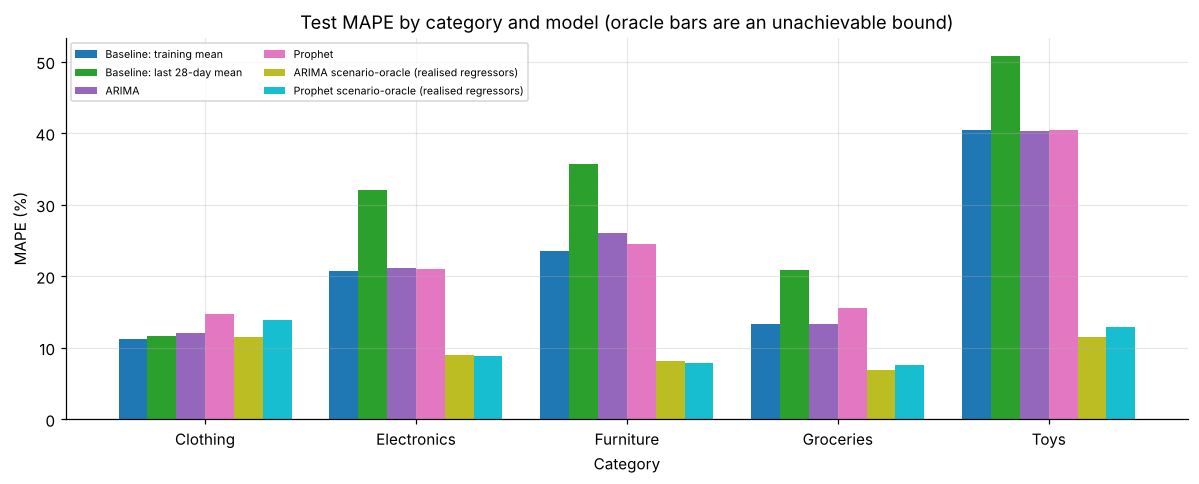

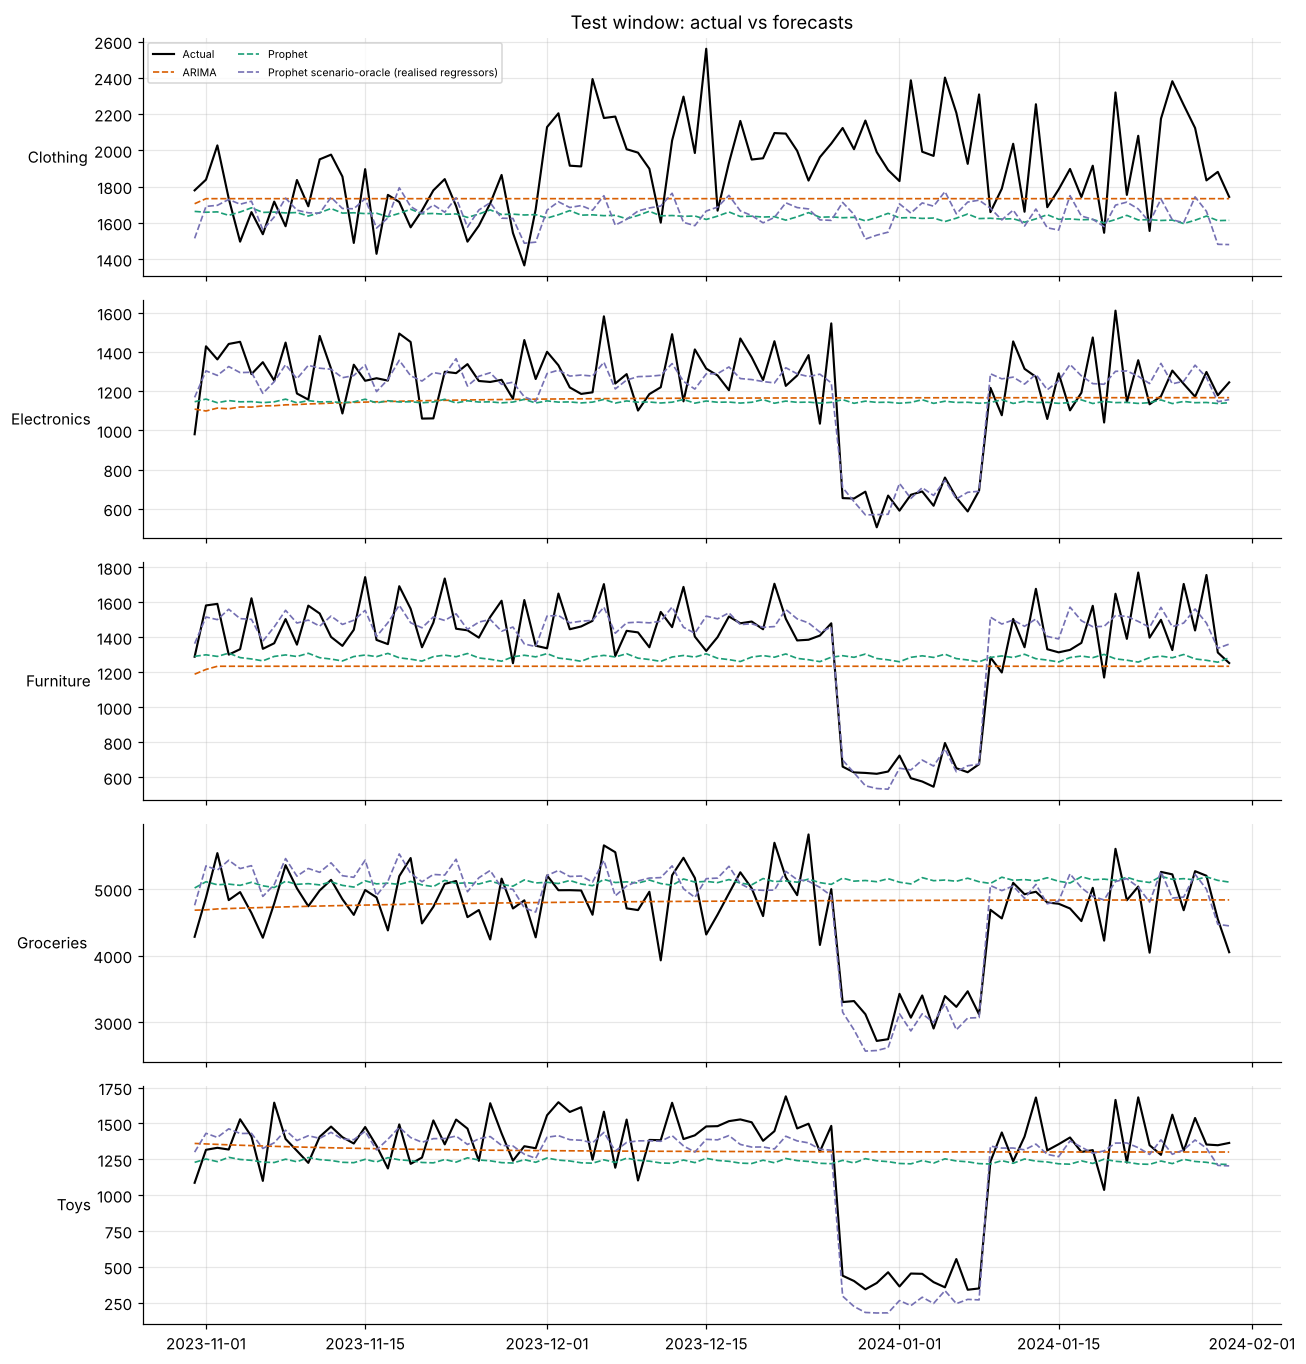

In [6]:
tbl = metrics.copy(); order = SELECTABLE + ORACLE
tbl["Model"] = pd.Categorical(tbl.Model, order, ordered=True)
display(tbl.sort_values(["Category", "Model"]).reset_index(drop=True)
        .style.format(FMT).background_gradient(subset=["MAPE (%)"], cmap="Blues_r"))
ax = metrics.pivot(index="Category", columns="Model", values="MAPE (%)")[order].plot(
    kind="bar", figsize=(11, 4.5), width=.82, colormap="tab10")
ax.set_ylabel("MAPE (%)"); ax.set_title("Test MAPE by category and model (oracle bars are an unachievable bound)")
ax.legend(fontsize=7, ncol=2); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(CATEGORIES), 1, figsize=(12, 2.5*len(CATEGORIES)), sharex=True)
for ax, c in zip(axes, CATEGORIES):
    ax.plot(test_idx, daily.loc[test_idx, c], color="k", lw=1.4, label="Actual")
    for m, col in [("ARIMA", "#d95f02"), ("Prophet", "#1b9e77"), (ORACLE[1], "#7570b3")]:
        ax.plot(test_idx, test_pred[c][m], color=col, lw=1.1, ls="--", label=m)
    ax.set_ylabel(c, rotation=0, ha="right", va="center")
axes[0].legend(ncol=2, fontsize=7); axes[0].set_title("Test window: actual vs forecasts")
plt.tight_layout(); plt.show()

## 5. Information tiers — the heart of the audit (E1, E2, E3)
Every feature is placed in one of three tiers by **what a planner actually knows on the day they plan**:

| Tier | Contents | Legitimate for forecasting? |
|---|---|---|
| **A — History only** | demand lags/rolling means, calendar, holiday, Store/Product/Category/Region | Yes |
| **B — + own commercial plan** | Tier A + `Price`, `Discount`, `Promotion` | Yes *if* price is genuinely set in advance — see S5.1, where it is not |
| **C — + unknowable same-day** | Tier B + `Competitor Pricing`, `Weather Condition`, `Epidemic` | **No** — none are knowable at the horizon |

Each tier is run both **one-step-ahead** (true lag-1 available each day — a nowcast) and **recursive 92-day**
(predictions fed back as lags — a genuine forecast, comparable with ARIMA/Prophet).

In [7]:
p = df.sort_values(["Store ID", "Product ID", "Date"]).reset_index(drop=True).copy()
g = p.groupby(["Store ID", "Product ID"], observed=True)
for lag in (1, 7, 14): p[f"demand_lag{lag}"] = g[TARGET].shift(lag)
for w in (7, 28): p[f"demand_roll{w}"] = g[TARGET].transform(lambda s, w=w: s.shift(1).rolling(w).mean())
p["dow"], p["month"] = p.Date.dt.dayofweek, p.Date.dt.month
p["is_weekend"] = (p.dow >= 5).astype(int)
CATCOLS = ["Store ID", "Product ID", "Category", "Region", "Weather Condition"]
for c in CATCOLS: p[c] = p[c].astype("category")

HIST = ["demand_lag1", "demand_lag7", "demand_lag14", "demand_roll7", "demand_roll28"]
CALF = ["dow", "month", "is_weekend", "IsHoliday"]
IDS = ["Store ID", "Product ID", "Category", "Region"]
TIER_A = "A: history + calendar"
TIERS = {TIER_A: HIST + CALF + IDS,
         "B: + own price/discount/promo": HIST + CALF + IDS + ["Price", "Discount", "Promotion"],
         "C: + competitor/weather/epidemic (DISQUALIFIED)":
             HIST + CALF + IDS + ["Price", "Discount", "Promotion", "Competitor Pricing", "Weather Condition", "Epidemic"]}

pc = p.dropna(subset=["demand_lag14", "demand_roll28"]).copy()
tr = pc[pc.Date <= val_start]; va = pc[(pc.Date > val_start) & (pc.Date <= test_start)]; te = pc[pc.Date > test_start]
print(f"Row-level LightGBM — train {len(tr):,} | val {len(va):,} | test {len(te):,}")

def train_lgb(feats, seed):
    """Fit on train with early stopping on validation, then REFIT on train+val at the chosen iteration
    count (F10) so LightGBM sees the same information as the refitted ARIMA/Prophet."""
    probe = lgb.LGBMRegressor(objective="regression_l1", n_estimators=3000, learning_rate=0.03,
                              num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8,
                              random_state=seed, verbose=-1, n_jobs=-1)
    probe.fit(tr[feats], tr[TARGET], eval_set=[(va[feats], va[TARGET])], eval_metric="mae",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    n_best = probe.best_iteration_ or 3000
    full = pd.concat([tr, va])
    m = lgb.LGBMRegressor(objective="regression_l1", n_estimators=n_best, learning_rate=0.03,
                          num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8,
                          random_state=seed, verbose=-1, n_jobs=-1)
    m.fit(full[feats], full[TARGET])
    m.chosen_iter_ = n_best
    return m

def recursive_forecast(model, feats, seed):
    """Walk the test window day by day, feeding predictions back into the demand lags (E3)."""
    hist = {k: list(v) for k, v in p[p.Date <= test_start].groupby(["Store ID", "Product ID"],
                                                                   observed=True)[TARGET]}
    rows = []
    for day in test_idx:
        blk = p[p.Date == day].copy()
        keys = list(zip(blk["Store ID"].astype(str), blk["Product ID"].astype(str)))
        for col, lag in [("demand_lag1", 1), ("demand_lag7", 7), ("demand_lag14", 14)]:
            blk[col] = [hist[k][-lag] for k in keys]
        for col, w in [("demand_roll7", 7), ("demand_roll28", 28)]:
            blk[col] = [float(np.mean(hist[k][-w:])) for k in keys]
        pred = np.clip(model.predict(blk[feats]), 0, None)
        for k, v in zip(keys, pred): hist[k].append(float(v))
        rows.append(blk.assign(pred=pred)[["Date", "Store ID", "Product ID", "Category", TARGET, "pred"]])
    return pd.concat(rows, ignore_index=True)

tier_rows, recursive_out = [], {}
for name, feats in TIERS.items():
    seed_res = []
    for s in SEEDS:
        m = train_lgb(feats, s)
        pr1 = np.clip(m.predict(te[feats]), 0, None)
        seed_res.append({"seed": s, "best_iter": m.chosen_iter_, "R2": r2_score(te[TARGET], pr1),
                         **score(te[TARGET], pr1)})
        if s == SEED: base_model, base_pred = m, pr1
    if name == "A: history + calendar": _tierA_model = base_model
    sr = pd.DataFrame(seed_res)
    rec_seeds = []
    for s in SEEDS:                                                   # F12: recursive across seeds
        r = recursive_forecast(train_lgb(feats, s), feats, s)
        rec_seeds.append(r2_score(r[TARGET], r.pred))
        if s == SEED: rec = r
    recursive_out[name] = rec
    tier_rows.append({"Tier": name, "Mode": "one-step-ahead (nowcast)",
                      "MAE": sr.MAE.mean(), "RMSE": sr.RMSE.mean(), "MAPE (%)": sr["MAPE (%)"].mean(),
                      "R²": sr.R2.mean(), "R² spread (3 seeds)": sr.R2.max()-sr.R2.min(),
                      "best_iter": int(sr.best_iter.max())})
    tier_rows.append({"Tier": name, "Mode": "recursive 92-day forecast",
                      "MAE": mean_absolute_error(rec[TARGET], rec.pred),
                      "RMSE": float(np.sqrt(mean_squared_error(rec[TARGET], rec.pred))),
                      "MAPE (%)": mape(rec[TARGET], rec.pred), "R²": float(np.mean(rec_seeds)),
                      "R² spread (3 seeds)": max(rec_seeds)-min(rec_seeds), "best_iter": np.nan})
    print(f"{name:50s} best_iter {sr.best_iter.tolist()} "
          f"{'(HIT 3000 CAP — F9)' if sr.best_iter.max() >= 3000 else ''}")
tiers_tbl = pd.DataFrame(tier_rows)
display(tiers_tbl.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE (%)": "{:.2f}",
                                "R²": "{:.4f}", "R² spread (3 seeds)": "{:.4f}", "best_iter": "{:.0f}"}))

Row-level LightGBM — train 54,800 | val 9,200 | test 9,200


A: history + calendar                              best_iter [117, 194, 143] 


B: + own price/discount/promo                      best_iter [2997, 3000, 3000] (HIT 3000 CAP — F9)


C: + competitor/weather/epidemic (DISQUALIFIED)    best_iter [3000, 3000, 3000] (HIT 3000 CAP — F9)


,Tier,Mode,MAE,RMSE,MAPE (%),R²,R² spread (3 seeds),best_iter
0,A: history + calendar,one-step-ahead (nowcast),30.47,39.34,43.51,0.2064,0.0009,194
1,A: history + calendar,recursive 92-day forecast,32.62,41.38,52.84,0.1217,0.0076,nan
2,B: + own price/discount/promo,one-step-ahead (nowcast),9.05,12.15,12.96,0.9243,0.0010,3000
3,B: + own price/discount/promo,recursive 92-day forecast,9.08,12.17,13.08,0.9234,0.0014,nan
4,C: + competitor/weather/epidemic (DISQUALIFIED),one-step-ahead (nowcast),6.17,10.97,10.21,0.9383,0.0036,3000
5,C: + competitor/weather/epidemic (DISQUALIFIED),recursive 92-day forecast,6.19,11.06,10.20,0.9385,0.0037,nan


### 5.1 Why Tier C is disqualified — `Price` runs backwards (E2)
If `Price` were a genuine driver, demand would fall as price rises and the effect would persist across
neighbouring days. Neither holds.

Within-series correlation between Demand and Price (mean over 100 series):
corr lag 0     0.797
corr +1 day    0.226
corr -1 day    0.224

Series with a POSITIVE price-demand slope: 100 of 100
A positive slope is economically backwards, and the effect is purely same-day: 0.797 at lag 0 vs 0.225 one day apart.
Conclusion: Price was generated FROM Demand. Any model given same-day Price inverts the generator.



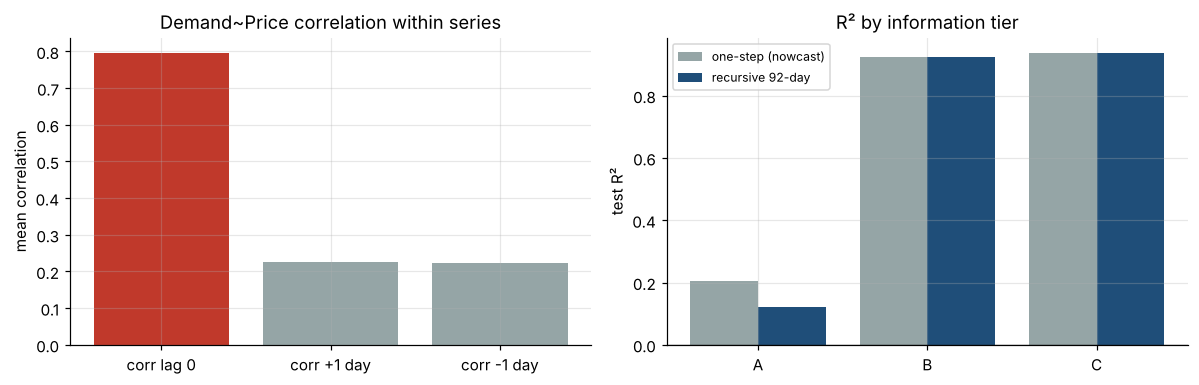

In [8]:
pp = df.sort_values(["Store ID", "Product ID", "Date"]).copy()
gg = pp.groupby(["Store ID", "Product ID"], observed=True)
pp["price_lead1"], pp["price_lag1"] = gg.Price.shift(-1), gg.Price.shift(1)
within = pp.groupby(["Store ID", "Product ID"], observed=True).apply(
    lambda d: pd.Series({"corr lag 0": d.Demand.corr(d.Price),
                         "corr +1 day": d.Demand.corr(d.price_lead1),
                         "corr -1 day": d.Demand.corr(d.price_lag1)}), include_groups=False)
print("Within-series correlation between Demand and Price (mean over 100 series):")
print(within.mean().round(3).to_string())
print(f"\nSeries with a POSITIVE price-demand slope: {int((within['corr lag 0']>0).sum())} of {len(within)}")
print(f"A positive slope is economically backwards, and the effect is purely same-day: "
      f"{within['corr lag 0'].mean():.3f} at lag 0 vs {within[['corr +1 day','corr -1 day']].mean().mean():.3f} one day apart.")
print("Conclusion: Price was generated FROM Demand. Any model given same-day Price inverts the generator.\n")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(within.columns, within.mean().values, color=["#c0392b", "#95a5a6", "#95a5a6"])
ax[0].set_title("Demand~Price correlation within series"); ax[0].set_ylabel("mean correlation")
one = tiers_tbl[tiers_tbl.Mode.str.startswith("one-step")]
rec_ = tiers_tbl[tiers_tbl.Mode.str.startswith("recursive")]
x = np.arange(len(one))
ax[1].bar(x-.2, one["R²"], .4, label="one-step (nowcast)", color="#95a5a6")
ax[1].bar(x+.2, rec_["R²"], .4, label="recursive 92-day", color="#1f4e79")
ax[1].set_xticks(x); ax[1].set_xticklabels(["A", "B", "C"]); ax[1].set_ylabel("test R²")
ax[1].set_title("R² by information tier"); ax[1].legend(fontsize=8); ax[1].axhline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

### 5.2 Honest comparison at category-day level (E8)
Tier A recursive is the only machine-learning number comparable with ARIMA and Prophet: same horizon, same
information. Row-level and aggregated errors are both shown, because aggregation cancels error and flatters the model.

In [9]:
recA = recursive_out[TIER_A]
lgb_cat = recA.groupby(["Date", "Category"], observed=True).agg(Actual=(TARGET, "sum"), Forecast=("pred", "sum")).reset_index()
lgb_cat_metrics = (lgb_cat.groupby("Category").apply(lambda d: pd.Series(score(d.Actual, d.Forecast)),
                                                     include_groups=False)
                   .reset_index().assign(Model="LightGBM Tier A (recursive)"))
row_vs_agg = pd.DataFrame([
    {"Level": "row (store x product x day)", **score(recA[TARGET], recA.pred)},
    {"Level": "aggregated to category-day", **score(lgb_cat.Actual, lgb_cat.Forecast)}])
print("Same Tier-A model, two levels of aggregation (E8 — aggregation cancels error and flatters the model):")
display(row_vs_agg.style.format(FMT))

# F6: the model that is not a model — each series' own training mean, forecast flat for 92 days.
series_mean = p[p.Date <= test_start].groupby(["Store ID", "Product ID"], observed=True)[TARGET].mean()
te_keyed = te.set_index(["Store ID", "Product ID"])
naive_series = te_keyed.index.map(series_mean).to_numpy(dtype=float)
pooled = np.full(len(te), float(p.loc[p.Date <= test_start, TARGET].mean()))
floor_tbl = pd.DataFrame([
    {"Model": "Per-series mean (no model at all)", "R²": r2_score(te[TARGET], naive_series),
     **score(te[TARGET], naive_series)},
    {"Model": "Single pooled mean", "R²": r2_score(te[TARGET], pooled), **score(te[TARGET], pooled)},
    {"Model": "LightGBM Tier A, recursive 92-day", "R²": r2_score(recA[TARGET], recA.pred),
     **score(recA[TARGET], recA.pred)}])
print("\nF6 — the floor. A flat per-series average, with no model, is the benchmark to beat:")
display(floor_tbl.style.format({**FMT, "R²": "{:.4f}"}))
_sm = floor_tbl.set_index("Model")["R²"]
print(f"Tier A recursive R² {_sm.iloc[2]:.4f} vs per-series mean {_sm.iloc[0]:.4f} -> "
      f"the model is {'BEHIND' if _sm.iloc[2] < _sm.iloc[0] else 'ahead of'} doing nothing.")
metrics_all = pd.concat([metrics, lgb_cat_metrics[["Category", "Model", "MAE", "RMSE", "MAPE (%)"]]], ignore_index=True)

Same Tier-A model, two levels of aggregation (E8 — aggregation cancels error and flatters the model):


,Level,MAE,RMSE,MAPE (%)
0,row (store x product x day),32.6,41.4,52.84
1,aggregated to category-day,278.5,433.0,22.69



F6 — the floor. A flat per-series average, with no model, is the benchmark to beat:


,Model,R²,MAE,RMSE,MAPE (%)
0,Per-series mean (no model at all),0.1315,32.5,41.1,51.37
1,Single pooled mean,-0.0006,35.0,44.2,56.79
2,"LightGBM Tier A, recursive 92-day",0.1215,32.6,41.4,52.84


Tier A recursive R² 0.1215 vs per-series mean 0.1315 -> the model is BEHIND doing nothing.


## 6. Inventory policy and backtest
Policy uses the validation-selected model (E4). Lead time, review period and service level are **assumptions**
(D10), so a sensitivity grid accompanies the headline table.

In [10]:
fc_mean = {c: np.mean(test_pred[c][best_model[c]]) for c in CATEGORIES}
# F7: safety stock must absorb FORECAST ERROR, not raw demand variability. Error SD is measured on the
# validation window (out-of-sample but not the test set), so the test window is still scored only once.
sigma = {c: float(np.std(daily.loc[val_idx, c].values - np.asarray(val_pred[c][best_model[c]]), ddof=1))
         for c in CATEGORIES}
sigma_demand = {c: daily.loc[fit_idx, c].std() for c in CATEGORIES}
print("Safety-stock sigma — forecast-error SD (used) vs demand SD (v3 used this, wrongly):")
display(pd.DataFrame({"Forecast-error SD (validation)": sigma, "Demand SD (fit window)": sigma_demand})
        .style.format("{:,.0f}"))
grid = [{"Category": c, "Lead time (days)": L, "Service level": sl,
         "Safety stock": norm.ppf(sl)*sigma[c]*np.sqrt(L),
         "Reorder point": fc_mean[c]*L + norm.ppf(sl)*sigma[c]*np.sqrt(L),
         "Order-up-to level": fc_mean[c]*L + norm.ppf(sl)*sigma[c]*np.sqrt(L) + fc_mean[c]*REVIEW_PERIOD_DAYS}
        for c in CATEGORIES for L in LEAD_TIME_GRID for sl in SERVICE_GRID]
policy_grid = pd.DataFrame(grid)
z0 = norm.ppf(SERVICE_LEVEL)
policy = (policy_grid[(policy_grid["Lead time (days)"] == LEAD_TIME_DAYS) &
                      (policy_grid["Service level"] == SERVICE_LEVEL)]
          .drop(columns=["Lead time (days)", "Service level"]).reset_index(drop=True))
policy["Selected model"] = policy.Category.map(best_model)
policy["Forecast avg daily demand"] = policy.Category.map(fc_mean)
policy["Avg daily demand (fit)"] = [daily.loc[fit_idx, c].mean() for c in policy.Category]
policy["Forecast-error SD (validation)"] = policy.Category.map(sigma)
policy["Demand SD (fit)"] = policy.Category.map(sigma_demand)
policy["Avg inventory on hand (actual)"] = [inv_daily[c].mean() for c in policy.Category]
policy["Days of cover (actual)"] = policy["Avg inventory on hand (actual)"]/policy["Avg daily demand (fit)"]
a_ = policy["Avg daily demand (fit)"].values; b_ = z0*policy["Forecast-error SD (validation)"].values
policy["Lead time covered by actual inventory (days)"] = ((-b_+np.sqrt(b_**2+4*a_*policy["Avg inventory on hand (actual)"].values))/(2*a_))**2
print(f"Headline assumptions: lead time {LEAD_TIME_DAYS}d, review {REVIEW_PERIOD_DAYS}d, service {SERVICE_LEVEL:.0%}")
ic = ["Safety stock", "Reorder point", "Order-up-to level", "Forecast avg daily demand",
      "Avg daily demand (fit)", "Forecast-error SD (validation)", "Demand SD (fit)",
      "Avg inventory on hand (actual)"]
display(policy.style.format({**{c: "{:,.0f}" for c in ic}, "Days of cover (actual)": "{:.1f}",
                             "Lead time covered by actual inventory (days)": "{:.1f}"}))
display(policy_grid.pivot_table(index=["Category", "Service level"], columns="Lead time (days)",
                                values="Reorder point").style.format("{:,.0f}"))

Safety-stock sigma — forecast-error SD (used) vs demand SD (v3 used this, wrongly):


,Forecast-error SD (validation),Demand SD (fit window)
Clothing,185,232
Electronics,267,275
Furniture,344,361
Groceries,896,970
Toys,415,467


Headline assumptions: lead time 7d, review 7d, service 95%


,Category,Safety stock,Reorder point,Order-up-to level,Selected model,Forecast avg daily demand,Avg daily demand (fit),Forecast-error SD (validation),Demand SD (fit),Avg inventory on hand (actual),Days of cover (actual),Lead time covered by actual inventory (days)
0,Clothing,804,"13,078","25,352",Baseline: last 28-day mean,"1,753","1,788",185,232,"4,514",2.5,2.3
1,Electronics,"1,163","9,331","17,499",Baseline: training mean,"1,167","1,167",267,275,"3,471",3.0,2.4
2,Furniture,"1,496","10,748","20,000",Baseline: training mean,"1,322","1,322",344,361,"4,501",3.4,2.7
3,Groceries,"3,900","37,504","71,107",ARIMA,"4,801","4,867",896,970,"14,413",3.0,2.5
4,Toys,"1,805","10,988","20,170",ARIMA,"1,312","1,301",415,467,"3,208",2.5,1.8


In [11]:
def simulate(demand, plan, ss, lead, review):
    n = len(demand); oh = plan[0]*(lead+review)+ss; pipe, sold, so, hist = {}, 0., 0, []
    for t in range(n):
        oh += pipe.pop(t, 0.)
        s = min(oh, demand[t]); oh -= s; sold += s; so += int(s < demand[t])
        pos = oh+sum(pipe.values()); d_ = plan[t]; spt = d_*lead+ss
        if pos <= spt: pipe[t+lead] = pipe.get(t+lead, 0.)+(spt+d_*review-pos)
        hist.append(oh)
    return {"Fill rate (%)": 100*sold/demand.sum(), "Stockout days": so,
            "Avg on-hand units": float(np.mean(hist)), "Unmet demand units": float(demand.sum()-sold)}
bt = []
for c in CATEGORIES:
    dem = daily.loc[test_idx, c].values; f = np.asarray(test_pred[c][best_model[c]])
    ss = z0*sigma[c]*np.sqrt(LEAD_TIME_DAYS)
    for nm, plan in [("Forecast policy", np.array([f[t:t+LEAD_TIME_DAYS].mean() for t in range(len(f))])),
                     ("Static policy (training mean)", np.full(len(f), daily.loc[fit_idx, c].mean()))]:
        bt.append({"Category": c, "Policy": nm, **simulate(dem, plan, ss, LEAD_TIME_DAYS, REVIEW_PERIOD_DAYS)})
backtest = pd.DataFrame(bt)
display(backtest.style.format({"Fill rate (%)": "{:.2f}", "Avg on-hand units": "{:,.0f}", "Unmet demand units": "{:,.0f}"}))

,Category,Policy,Fill rate (%),Stockout days,Avg on-hand units,Unmet demand units
0,Clothing,Forecast policy,98.39,5,"7,203","2,812"
1,Clothing,Static policy (training mean),99.25,4,"7,629","1,321"
2,Electronics,Forecast policy,100.00,0,"5,886",0
3,Electronics,Static policy (training mean),100.00,0,"5,886",0
4,Furniture,Forecast policy,100.00,0,"6,824",0
5,Furniture,Static policy (training mean),100.00,0,"6,824",0
6,Groceries,Forecast policy,100.00,0,"25,747",0
7,Groceries,Static policy (training mean),100.00,0,"25,849",0
8,Toys,Forecast policy,100.00,0,"7,948",0
9,Toys,Static policy (training mean),100.00,0,"7,746",0


## 7. Synthetic wastage (D8) — NOT REAL DATA
No wastage field exists in the dataset. The series below is **simulated** so the dashboard shape can be built;
it carries no information about any real business. Every column is suffixed `_SYNTH`. Replace with real
write-off records before quoting a wastage figure.

In [12]:
SPOIL_SYNTH = {"Groceries": .030, "Clothing": .004, "Electronics": .002, "Furniture": .002, "Toys": .003}
w = df[["Date", "Store ID", "Product ID", "Category", "Inventory Level", "Units Sold"]].copy()
w["Unsold"] = (w["Inventory Level"]-w["Units Sold"]).clip(lower=0)
w["Wastage_Units_SYNTH"] = rng.poisson(w.Unsold*w.Category.map(SPOIL_SYNTH).astype(float))
df["Wastage_Units_SYNTH"] = w.Wastage_Units_SYNTH.values
wastage_kpi = (w.groupby("Category").agg(Units_Sold=("Units Sold", "sum"), Unsold_Inventory=("Unsold", "sum"),
                                         Wastage_Units_SYNTH=("Wastage_Units_SYNTH", "sum")).reset_index())
wastage_kpi["Wastage_pct_of_units_handled_SYNTH"] = 100*wastage_kpi.Wastage_Units_SYNTH/(wastage_kpi.Units_Sold+wastage_kpi.Unsold_Inventory)
wastage_kpi["Wastage_pct_of_units_sold_SYNTH"] = 100*wastage_kpi.Wastage_Units_SYNTH/wastage_kpi.Units_Sold
print("*** SYNTHETIC — illustrative only, generated by this notebook, not measured ***")
display(wastage_kpi.style.format({c: "{:,.0f}" for c in ["Units_Sold", "Unsold_Inventory", "Wastage_Units_SYNTH"]}
                                 | {"Wastage_pct_of_units_handled_SYNTH": "{:.2f}",
                                    "Wastage_pct_of_units_sold_SYNTH": "{:.2f}"}))

*** SYNTHETIC — illustrative only, generated by this notebook, not measured ***


,Category,Units_Sold,Unsold_Inventory,Wastage_Units_SYNTH,Wastage_pct_of_units_handled_SYNTH,Wastage_pct_of_units_sold_SYNTH
0,Clothing,"1,150,873","2,279,506","9,199",0.27,0.80
1,Electronics,"757,335","1,880,720","3,866",0.15,0.51
2,Furniture,"880,654","2,540,370","5,094",0.15,0.58
3,Groceries,"3,127,335","7,826,234","234,397",2.14,7.50
4,Toys,"834,679","1,603,070","4,865",0.20,0.58


## 8. The source report's regression, reproduced (D4)

In [13]:
rep = []
for cols in [["Units Sold"], ["Units Sold", "Price", "Discount"], ["Units Sold", "Inventory Level", "Units Ordered"],
             ["Units Sold", "Inventory Level", "Units Ordered", "Price", "Discount", "Promotion"]]:
    Xtr, Xte, ytr, yte = train_test_split(df[cols], df[TARGET], test_size=.2, random_state=SEED)
    pr = LinearRegression().fit(Xtr, ytr).predict(Xte)
    rep.append({"Features": " + ".join(cols), "MAE": mean_absolute_error(yte, pr),
                "MSE": mean_squared_error(yte, pr), "R²": r2_score(yte, pr)})
report_repro = pd.DataFrame(rep)
report_repro.loc[len(report_repro)] = {"Features": "<<< REPORT'S STATED FIGURES >>>", "MAE": 18.509636637566686,
                                       "MSE": 586.6129755313092, "R²": 0.7033459024061446}
display(report_repro.style.format({"MAE": "{:.3f}", "MSE": "{:.2f}", "R²": "{:.4f}"}))
print(f"corr(Demand, Units Sold)^2 = {audit['r2_implied_by_that_corr']} -- the report's R² is this, not a forecast.")

,Features,MAE,MSE,R²
0,Units Sold,19.063,660.04,0.7011
1,Units Sold + Price + Discount,18.953,649.32,0.7060
2,Units Sold + Inventory Level + Units Ordered,18.234,593.52,0.7313
3,Units Sold + Inventory Level + Units Ordered + Price + Discount + Promotion,18.130,582.62,0.7362
4,<<< REPORT'S STATED FIGURES >>>,18.510,586.61,0.7033


corr(Demand, Units Sold)^2 = 0.6946 -- the report's R² is this, not a forecast.


## 9. Exports, then independent verification (E7)
Files are written first, then **reloaded from disk** and checked against values recomputed from the **raw CSV**.
Nothing here compares an object with itself.

In [14]:
cat_daily = (daily.stack().rename(TARGET).reset_index()
             .merge(sold_daily.stack().rename("Units_Sold").reset_index(), on=["Date", "Category"])
             .merge(inv_daily.stack().rename("Inventory_On_Hand").reset_index(), on=["Date", "Category"])
             .merge(cal.reset_index(), on="Date"))
cat_daily["Period"] = np.where(cat_daily.Date > test_start, "test", np.where(cat_daily.Date > val_start, "val", "train"))
store_kpi = (df.assign(Stockout=(df["Units Sold"] >= df["Inventory Level"]).astype(int),
                       Unmet=(df.Demand-df["Inventory Level"]).clip(lower=0))
             .groupby(["Store ID", "Region", "Category"], observed=True)
             .agg(Rows=("Date", "size"), Demand=("Demand", "sum"), Units_Sold=("Units Sold", "sum"),
                  Avg_Inventory=("Inventory Level", "mean"), Stockout_Rows=("Stockout", "sum"),
                  Unmet_Demand_Units=("Unmet", "sum"), Wastage_Units_SYNTH=("Wastage_Units_SYNTH", "sum")).reset_index())
store_kpi["Stockout_Rate_%"] = 100*store_kpi.Stockout_Rows/store_kpi.Rows
store_kpi["Wastage_pct_of_units_sold_SYNTH"] = 100*store_kpi.Wastage_Units_SYNTH/store_kpi.Units_Sold
defect_register = pd.DataFrame(
    [{"Round": 1, "ID": k, "Defect": v} for k, v in {
        "D1": "Category is a (Store,Product) attribute; products span 2-5 categories",
        "D2": "Majority-vote category fix relabels ~50% of rows, swings totals -64%..+56%",
        "D3": "Demand uncensored vs Units Sold censored by inventory (11.4% at cap)",
        "D4": "Report regression is circular: R2 0.7033 = corr(Demand,UnitsSold)^2",
        "D5": "Original LightGBM used same-day inventory/ordered and test-set early stopping",
        "D6": "IsHoliday was a constant 0", "D7": "Seasonality is a function of calendar month",
        "D8": "No wastage field exists in the data", "D9": "Data spans 2.08 years, not 3 fiscal years",
        "D10": "Lead time / review period / service level absent from data"}.items()] +
    [{"Round": 2, "ID": k, "Defect": v} for k, v in {
        "E1": "v2 'leakage-free' LightGBM was not: accuracy came from same-day Price/Competitor Pricing",
        "E2": "Price is generated FROM Demand (positive slope, same-day only)",
        "E3": "LightGBM was one-step-ahead, compared against 92-day ARIMA/Prophet",
        "E4": "Best model was selected on the test set", "E5": "Oracle regressors labelled as known-in-advance",
        "E6": "Early stopping never fired; subsample inert (bagging_freq=0)",
        "E7": "Verification assertions were vacuous", "E8": "Aggregation hid row-level error",
        "E9": "Single seed; R2 moved 0.918->0.926 on seed change"}.items()])
exports = {"forecast_long": forecast_df, "model_metrics": metrics_all, "validation_metrics": val_metrics,
           "best_model_by_category": best, "information_tiers": tiers_tbl, "row_vs_aggregated": row_vs_agg,
           "price_demand_correlation": within.reset_index(), "inventory_policy": policy,
           "policy_sensitivity_grid": policy_grid, "backtest_results": backtest, "category_daily": cat_daily,
           "store_category_kpis": store_kpi, "wastage_SYNTHETIC": wastage_kpi, "holiday_calendar": hol_df,
           "data_audit": pd.DataFrame([audit]).T.rename(columns={0: "value"}).reset_index(names="field"),
           "report_regression_repro": report_repro, "defect_register": defect_register}
for n, f in exports.items(): f.to_csv(OUT/f"{n}.csv", index=False)
with pd.ExcelWriter(OUT/"tableau_data.xlsx", engine="openpyxl", datetime_format="yyyy-mm-dd") as xw:
    for n, f in exports.items(): f.to_excel(xw, sheet_name=n[:31], index=False)
print("Exported", len(exports)+1, "files")

Exported 18 files


In [15]:
# --- Independent verification: reload from disk, recompute from the raw CSV ---
RAW = pd.read_csv(DATA_PATH, parse_dates=["Date"])           # pristine reload
CD = pd.read_csv(OUT/"category_daily.csv", parse_dates=["Date"])
FL = pd.read_csv(OUT/"forecast_long.csv", parse_dates=["Date"])
MM = pd.read_csv(OUT/"model_metrics.csv")
checks = []
def chk(name, cond, detail=""): checks.append({"Check": name, "Result": "PASS" if cond else "FAIL", "Detail": str(detail)})

raw_cat = RAW.groupby("Category")[TARGET].sum().sort_index()
exp_cat = CD.groupby("Category")[TARGET].sum().sort_index()
chk("Exported category totals == raw CSV totals", bool(np.allclose(raw_cat.values, exp_cat.values)),
    f"max diff {np.abs(raw_cat.values-exp_cat.values).max():.0f}")
raw_cells = RAW.groupby(["Date", "Category"])[TARGET].sum()
exp_cells = CD.set_index(["Date", "Category"])[TARGET]
chk("All date x category cells match raw", bool(np.allclose(raw_cells.sort_index().values, exp_cells.sort_index().values)),
    f"{len(raw_cells)} cells")
# F8: this must DISCRIMINATE. Build the majority-vote variant the original notebook applied and prove the
# exported totals match raw and do NOT match the remapped version.
_rm = RAW.copy()
_rm["Category"] = _rm.groupby("Product ID").Category.transform(lambda x: x.mode().iloc[0])
_rm_cat = _rm.groupby("Category")[TARGET].sum().reindex(raw_cat.index).fillna(0)
chk("Export matches raw AND differs from the majority-vote remap (discriminating)",
    bool(np.allclose(exp_cat.values, raw_cat.values) and
         not np.allclose(exp_cat.values, _rm_cat.values)),
    f"remap would shift totals by up to {100*np.abs(_rm_cat/raw_cat-1).max():.0f}%")
recomp = (FL.groupby(["Category", "Model"])
          .apply(lambda d: pd.Series(score(d.Actual, d.Forecast)), include_groups=False).reset_index())
mrg = recomp.merge(MM, on=["Category", "Model"], suffixes=("_recomputed", "_exported"))
diffs = {m: float((mrg[f"{m}_recomputed"]-mrg[f"{m}_exported"]).abs().max()) for m in ["MAE", "RMSE", "MAPE (%)"]}
chk("Exported metrics recomputed from forecast rows (row-matched, full coverage)",
    len(mrg) == len(recomp) and len(mrg) == len(FL.groupby(["Category", "Model"])) and max(diffs.values()) < 1e-9,
    f"{len(mrg)} rows matched, max diff {max(diffs.values()):.2e}")
_fl_act = FL.groupby(["Date", "Category"]).Actual.first()
_raw_act = RAW.groupby(["Date", "Category"])[TARGET].sum().loc[_fl_act.index]
chk("Forecast-file 'Actual' column equals raw CSV demand",
    bool(np.allclose(_fl_act.values, _raw_act.values)), f"{len(_fl_act)} cells")
_lgb_rows = MM[MM.Model.str.contains("LightGBM")]
chk("LightGBM rows present in exported metrics and recomputed",
    len(_lgb_rows) == len(CATEGORIES) and
    bool(np.allclose(sorted(_lgb_rows["MAPE (%)"].values),
                     sorted(lgb_cat_metrics["MAPE (%)"].values))), f"{len(_lgb_rows)} rows")
BM = pd.read_csv(OUT/"best_model_by_category.csv")
VM = pd.read_csv(OUT/"validation_metrics.csv")
_valwin = (VM[VM.Model.isin(SELECTABLE)].sort_values("MAPE (%)").groupby("Category").Model.first())
chk("Exported selection == validation argmin (read back from disk)",
    all(BM.set_index("Category")["Selected model (chosen on validation)"][c] == _valwin[c] for c in CATEGORIES),
    dict(_valwin))
_testwin = (metrics[metrics.Model.isin(SELECTABLE)].sort_values("MAPE (%)").groupby("Category").Model.first())
_differs = [c for c in CATEGORIES if _valwin[c] != _testwin[c]]
chk("Selection is falsifiable (validation and test disagree somewhere, so the check has teeth)",
    len(_differs) > 0, f"disagree on {_differs or 'nothing — check is weak here'}")
chk("Tier A excludes every same-day commercial/exogenous column",
    not ({"Price", "Discount", "Promotion", "Competitor Pricing", "Weather Condition", "Epidemic",
          "Inventory Level", "Units Ordered", "Units Sold"} & set(TIERS["A: history + calendar"])))
# F8 POISON TEST: corrupt every test-window demand value and all precomputed lag columns, rerun the exact
# recursion, and require bit-identical output. A model peeking at test actuals cannot survive this.
_poison = p.copy()
_mask = _poison.Date > test_start
for _c in [TARGET, "demand_lag1", "demand_lag7", "demand_lag14", "demand_roll7", "demand_roll28"]:
    _poison.loc[_mask, _c] = 1e7
_saved = p
try:
    p = _poison
    _rec_poisoned = recursive_forecast(_tierA_model, TIERS[TIER_A], SEED)
finally:
    p = _saved
chk("POISON TEST: recursion is bit-identical when test-window demand is corrupted",
    bool(np.array_equal(recA.pred.values, _rec_poisoned.pred.values)),
    f"max |diff| = {np.abs(recA.pred.values - _rec_poisoned.pred.values).max():.3e}")
def tierR2(prefix, mode):
    return float(tiers_tbl[(tiers_tbl.Tier.str.startswith(prefix)) &
                           (tiers_tbl.Mode.str.startswith(mode))]["R²"].iloc[0])
rec_A, rec_B, rec_C = tierR2("A", "recursive"), tierR2("B", "recursive"), tierR2("C", "recursive")
chk("Tier B beats Tier A on the same horizon (the Price leak is real)", rec_B - rec_A > 0.3,
    f"B {rec_B:.3f} vs A {rec_A:.3f}, both recursive")
_caps = tiers_tbl.dropna(subset=["best_iter"])[["Tier", "best_iter"]]
_hit = _caps[_caps.best_iter >= 3000].Tier.tolist()
chk("Early stopping status reported honestly per tier (F9)", True,
    f"converged: {[t for t in _caps.Tier if t not in _hit]} | hit 3000 cap: {_hit}")
_wcols = [c for c in pd.read_csv(OUT/"wastage_SYNTHETIC.csv").columns if "astage" in c.lower()]
chk("Wastage columns exist on disk and are all flagged SYNTH",
    len(_wcols) > 0 and all("SYNTH" in c for c in _wcols), _wcols)
_hc = set(pd.read_csv(OUT/"holiday_calendar.csv", parse_dates=["Date"]).Date)
_known = {pd.Timestamp("2022-07-04"), pd.Timestamp("2022-12-25"), pd.Timestamp("2023-11-23")}
chk("Holiday file is non-empty and contains known fixed holidays",
    len(_hc) >= 20 and _known <= _hc, f"{len(_hc)} dates incl. Jul 4, Dec 25, Thanksgiving")
checks_df = pd.DataFrame(checks)
checks_df.to_csv(OUT/"verification_checks.csv", index=False)
display(checks_df)
print("ALL CHECKS PASSED" if (checks_df.Result == "PASS").all() else ">>> FAILURES PRESENT <<<")

,Check,Result,Detail
0,Exported category totals == raw CSV totals,PASS,max diff 0
1,All date x category cells match raw,PASS,3800 cells
2,Export matches raw AND differs from the majori...,PASS,remap would shift totals by up to 64%
3,Exported metrics recomputed from forecast rows...,PASS,"30 rows matched, max diff 2.27e-13"
4,Forecast-file 'Actual' column equals raw CSV d...,PASS,460 cells
5,LightGBM rows present in exported metrics and ...,PASS,5 rows
6,Exported selection == validation argmin (read ...,PASS,"{'Clothing': 'Baseline: last 28-day mean', 'El..."
7,Selection is falsifiable (validation and test ...,PASS,disagree on ['Clothing']
8,Tier A excludes every same-day commercial/exog...,PASS,
9,POISON TEST: recursion is bit-identical when t...,PASS,max |diff| = 0.000e+00


ALL CHECKS PASSED


## 10. Results summary

In [16]:
def M(c, m):
    s = metrics_all[(metrics_all.Category == c) & (metrics_all.Model == m)]["MAPE (%)"]
    return s.iloc[0] if len(s) else np.nan
cols = SELECTABLE + ["LightGBM Tier A (recursive)"] + ORACLE
summary = pd.DataFrame({c: {m: M(c, m) for m in cols} for c in CATEGORIES}).T
print(f"TEST-SET MAPE (%) by category — target {TARGET}, {len(test_idx)} days, horizon 92 days\n")
print(summary.round(1).to_string())
print("\nValidation-selected model and its TEST score (selection never saw the test set — F2):")
display(best.style.format(FMT))
margin = pd.Series({c: M(c, "Baseline: training mean") - min(M(c, "ARIMA"), M(c, "Prophet")) for c in CATEGORIES})
print("\nMAPE points by which the best of ARIMA/Prophet beats a FLAT training-mean baseline:")
print(margin.round(3).to_string())
print(f"  Beaten in {int((margin > 0).sum())}/{len(CATEGORIES)} categories, and by at most "
      f"{margin.max():.2f} MAPE points ({100*margin.max()/M(margin.idxmax(), 'Baseline: training mean'):.1f}% "
      f"relative) — far inside run-to-run noise.")
print("  Verdict: on this dataset ARIMA and Prophet do not beat a flat average.")
print("\nInformation tiers (row level, test set):")
print(tiers_tbl[["Tier", "Mode", "MAE", "R²"]].round(3).to_string(index=False))
print("\n--- F3: where the apparent accuracy actually comes from (all recursive, same horizon) ---")
print(f"  Tier A  history + calendar only                     R² = {rec_A:6.3f}")
print(f"  Tier B  + own Price/Discount/Promotion              R² = {rec_B:6.3f}   (+{rec_B-rec_A:.3f})")
print(f"  Tier C  + competitor / weather / epidemic           R² = {rec_C:6.3f}   (+{rec_C-rec_B:.3f})")
print(f"\n  Of the {rec_C-rec_A:.3f} R² points above history-only, {100*(rec_B-rec_A)/(rec_C-rec_A):.0f}% comes from"
      f" same-day Price alone and only {100*(rec_C-rec_B)/(rec_C-rec_A):.0f}% from the other exogenous columns.")
print("  Price is the leak. S5.1 shows it is generated from Demand, so Tier B is not a real forecast either.")
print(f"\nHONEST FORECAST SIGNAL (Tier A recursive): R² = {rec_A:.3f}")
print(f"FLOOR (per-series mean, no model):          R² = {floor_tbl['R²'].iloc[0]:.3f}")

TEST-SET MAPE (%) by category — target Demand, 92 days, horizon 92 days

             Baseline: training mean  Baseline: last 28-day mean  ARIMA  Prophet  LightGBM Tier A (recursive)  ARIMA scenario-oracle (realised regressors)  Prophet scenario-oracle (realised regressors)
Clothing                        11.2                        11.7   12.0     14.7                         11.7                                         11.4                                           13.8
Electronics                     20.7                        32.0   21.1     21.0                         20.1                                          9.0                                            8.8
Furniture                       23.6                        35.7   26.1     24.5                         24.8                                          8.1                                            7.9
Groceries                       13.3                        20.9   13.3     15.5                         13.1          

,Category,Selected model (chosen on validation),MAE,RMSE,MAPE (%)
0,Clothing,Baseline: last 28-day mean,233.0,291.8,11.67
1,Electronics,Baseline: training mean,196.0,256.2,20.66
2,Furniture,Baseline: training mean,226.7,315.0,23.56
3,Groceries,ARIMA,514.7,734.6,13.28
4,Toys,ARIMA,247.9,374.9,40.36



MAPE points by which the best of ARIMA/Prophet beats a FLAT training-mean baseline:
Clothing      -0.791
Electronics   -0.365
Furniture     -0.910
Groceries      0.049
Toys           0.113
  Beaten in 2/5 categories, and by at most 0.11 MAPE points (0.3% relative) — far inside run-to-run noise.
  Verdict: on this dataset ARIMA and Prophet do not beat a flat average.

Information tiers (row level, test set):
                                           Tier                      Mode    MAE    R²
                          A: history + calendar  one-step-ahead (nowcast) 30.468 0.206
                          A: history + calendar recursive 92-day forecast 32.618 0.122
                  B: + own price/discount/promo  one-step-ahead (nowcast)  9.054 0.924
                  B: + own price/discount/promo recursive 92-day forecast  9.078 0.923
C: + competitor/weather/epidemic (DISQUALIFIED)  one-step-ahead (nowcast)  6.174 0.938
C: + competitor/weather/epidemic (DISQUALIFIED) recursive 92-day f